# Linear Regression Exercise: From Theory to Implementation

**Objective**: Learn to implement Linear Regression from scratch with different regularization methods.

**Learning Goals**:
- Understand the mathematical foundation of Linear Regression
- Implement gradient descent optimization
- Explore the effects of different learning rates
- Compare L1 and L2 regularization techniques
- Visualize and analyze results

---


## Part 1: Theory and Mathematical Foundation

### Linear Regression Model
The linear regression model can be written as:

$$\hat{y} = X\theta = \theta_0 + \theta_1 x_1 + \theta_2 x_2 + ... + \theta_n x_n$$

Where:
- $\hat{y}$ is the predicted value
- $X$ is the feature matrix (including bias term)
- $\theta$ is the parameter vector

### Cost Function
Mean Squared Error (MSE):
$$J(\theta) = \frac{1}{2m} \sum_{i=1}^{m} (h_\theta(x^{(i)}) - y^{(i)})^2$$

### Gradient Descent Update Rule
$$\theta := \theta - \alpha \frac{\partial J(\theta)}{\partial \theta}$$

Where $\alpha$ is the learning rate.


## Part 2: Setup 

First, let's import the necessary libraries and generate some sample data.


In [4]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
import seaborn as sns


# Set random seed for reproducibility
np.random.seed(0)
plt.style.use('default')
sns.set_palette("husl")


## Part 3: Linear Regression Implementation

Now let's implement Linear Regression from scratch using gradient descent.


In [6]:
class LinearRegression:
    def __init__(self, learning_rate=0.01, max_iterations=1000, regularization=None, lambda_reg=0.01):
        """
        Logistic Regression with Gradient Descent
        
        Parameters:
        -----------
        learning_rate : float, learning rate for gradient descent
        max_iterations : int, maximum number of iterations
        regularization : str, 'l1', 'l2', or None
        lambda_reg : float, regularization strength
        """
        self.learning_rate = learning_rate
        self.max_iterations = max_iterations
        self.regularization = regularization
        self.lambda_reg = lambda_reg
        self.cost_history = []
        self.weights = None
        
    def _add_bias(self, X):
        """Add bias term to feature matrix"""
        # TODO: Add a column of ones to X for the bias term
        # Hint: Use np.c_[ones, X] or np.column_stack
        return np.column_stack([np.ones(X.shape[0]), X])
    
    def _compute_cost(self, X, y):
        """Compute the cost function (MSE + regularization)"""
        
        # TODO: Compute predictions
        predictions = np.dot(X,self.weights)
        
        # TODO: Compute MSE cost
        mse_cost = np.mean((predictions-y)**2)
        
        # Add regularization
        reg_cost = 0
        if self.regularization == 'l1':
            # TODO: Add L1 regularization cost
            reg_cost = self.lambda_reg * np.sum(np.abs(self.weights[1:]))
        elif self.regularization == 'l2':
            # TODO: Add L2 regularization cost
            # Hint: L2 = lambda * sum(weights^2), exclude bias term (weights[0])
            reg_cost = self.lambda_reg * np.sum(self.weights[1:]**2)            
        return mse_cost + reg_cost
    
    def _compute_gradients(self, X, y):
        """Compute gradients of the cost function"""
        m = X.shape[0]
        y = y.ravel()
        
        # TODO: Compute predictions
        predictions = np.dot(X,self.weights)
        
        # TODO: Compute gradient
        err = (predictions - y).reshape(-1,1)
        gradients = 2 * np.dot(X.T,err) / m
        gradients = gradients.flatten()
        
        # Add regularization to gradients
        if self.regularization == 'l1':
            # TODO: Add L1 regularization to gradients
            # Hint: L1 gradient = lambda * sign(weights), don't regularize bias
            reg_grad = self.lambda_reg * np.sign(self.weights)
            reg_grad[0] = 0
            gradients += reg_grad

        elif self.regularization == 'l2':
            # TODO: Add L2 regularization to gradients
            # Hint: L2 gradient = 2 * lambda * weights, don't regularize bias
            reg_grad = 2 * self.lambda_reg * self.weights
            reg_grad[0] = 0
            gradients += reg_grad
            
        return gradients
    
    def fit(self, X, y):
        """Train the linear regression model"""
        # Add bias term
        X_with_bias = self._add_bias(X)
        
        # Initialize weights
        n_features = X_with_bias.shape[1]
        self.weights = np.random.randn(n_features) * 0.01
        
        # Training loop
        for i in range(self.max_iterations):
            # TODO: Compute cost and store in history
            cost = self._compute_cost(X_with_bias,y)
            self.cost_history.append(cost)
            
            # TODO: Compute gradients
            gradients = self._compute_gradients(X_with_bias,y)
            
            # TODO: Update weights using gradient descent
            self.weights -= self.learning_rate * gradients
            
            # Print progress every 100 iterations
            if (i + 1) % 100 == 0:
                print(f"Iteration {i+1}/{self.max_iterations}, Cost: {cost:.6f}")
    
    def predict(self, X):
        """Make predictions on new data"""
        X_with_bias = self._add_bias(X)
        return X_with_bias @ self.weights
    
    def get_weights(self):
        """Return the learned weights"""
        return self.weights
    def evaluate(self, X, y_true):
        y_pred = self.predict(X)
        m = X.shape[0]
        # Calculate MSE manually
        mse = np.sum((y_true - y_pred) ** 2) / m
        # Calculate mean of true values
        y_mean = np.mean(y_true)
        # Calculate R-squared manually
        ss_tot = np.sum((y_true - y_mean) ** 2)
        ss_res = np.sum((y_true - y_pred) ** 2)
        r2 = 1 - (ss_res / ss_tot) if ss_tot != 0 else 0.0
        return mse, r2


## Part 4: Visualization Functions

**Your Task**: Complete the visualization functions below.


In [8]:
def plot_cost_history(models_dict):
    """
    Plot cost history for multiple models
    
    Parameters:
    -----------
    models_dict : dict, {model_name: model_instance}
    """  
    # TODO: Plot cost history for each model
    plt.figure(figsize=(15,7))
    for name, model in models_dict.items():
        plt.plot(model.cost_history, label=name)
    plt.xlabel('Iterations')
    plt.ylabel('Cost')
    plt.title('Cost History')
    plt.legend()
    plt.show()

def compare_predictions(X_train, X_test, y_train, y_test, models_dict):
    """
    Compare predictions from multiple models
    
    Parameters:
    -----------
    X : ndarray, features
    y : ndarray, true targets  
    models_dict : dict, {model_name: model_instance}
    """
    n_models = len(models_dict)
    fig, axes = plt.subplots(1, n_models, figsize=(5*n_models, 5))
    
    if n_models == 1:
        axes = [axes]
    
    for idx, (name, model) in enumerate(models_dict.items()):
        # TODO: Complete the subplot for each model
        ax = axes[idx]
        ax.scatter(X_train, y_train, c='#FF9800', label='Train', alpha=0.7)
        ax.scatter(X_test,  y_test,  c='#D32F2F', label='Test',  alpha=0.7)
        X_line = np.linspace(X_train.min(), X_train.max(), 100).reshape(-1,1)
        ax.plot(X_line, model.predict(X_line), 'b-', label='Pred')
        ax.set_title(name); ax.set_xlabel('x1'); ax.set_ylabel('y')
        ax.legend()
    plt.tight_layout(); plt.show()

def plot_train_test_scatter(X_train, y_train, X_test, y_test):
    """
    Plot training and testing datasets side by side using scatter plots.
    
    Parameters:
    -----------
    X_train : array-like
        Feature(s) for training dataset.
    y_train : array-like
        Target values for training dataset.
    X_test : array-like
        Feature(s) for testing dataset.
    y_test : array-like
        Target values for testing dataset.
    """
    plt.figure(figsize=(15, 7))
    plt.subplot(1, 2, 1)
    plt.scatter(
        X_train, y_train,
        color='#FF9800',
        alpha=0.85,
        edgecolors='k',
        s=64,          
        linewidth=0.7
    )
    plt.title('Train Dataset', fontsize=12, weight='bold')
    plt.xlabel('$x_1$', fontsize=10)
    plt.ylabel('$y$', fontsize=10)
    plt.legend(['Train'], frameon=True, loc='best', fontsize=8)
    sns.despine()

    # Test set plot
    plt.subplot(1, 2, 2)
    plt.scatter(
        X_test, y_test,
        color='#D32F2F',            
        alpha=0.85,
        edgecolors='k',
        s=64,
        linewidth=0.7
    )
    plt.title('Test Dataset', fontsize=12, weight='bold')
    plt.xlabel('$x_2$', fontsize=10)
    plt.ylabel('$y$', fontsize=10)
    plt.legend(['Test'], frameon=True, loc='best', fontsize=8)
    sns.despine()

    plt.tight_layout(rect=[0, 0.03, 1, 0.97]) 
    plt.show()


## Part 4: Train univariate Regression Model

### Task 1: Specify Input & Target (Univariate Regression)

**Your Task**: Load and prepare the dataset for linear regression.

For the univariate model, load the feature x_1 and split the data into training and test sets with an 80/20 ratio.

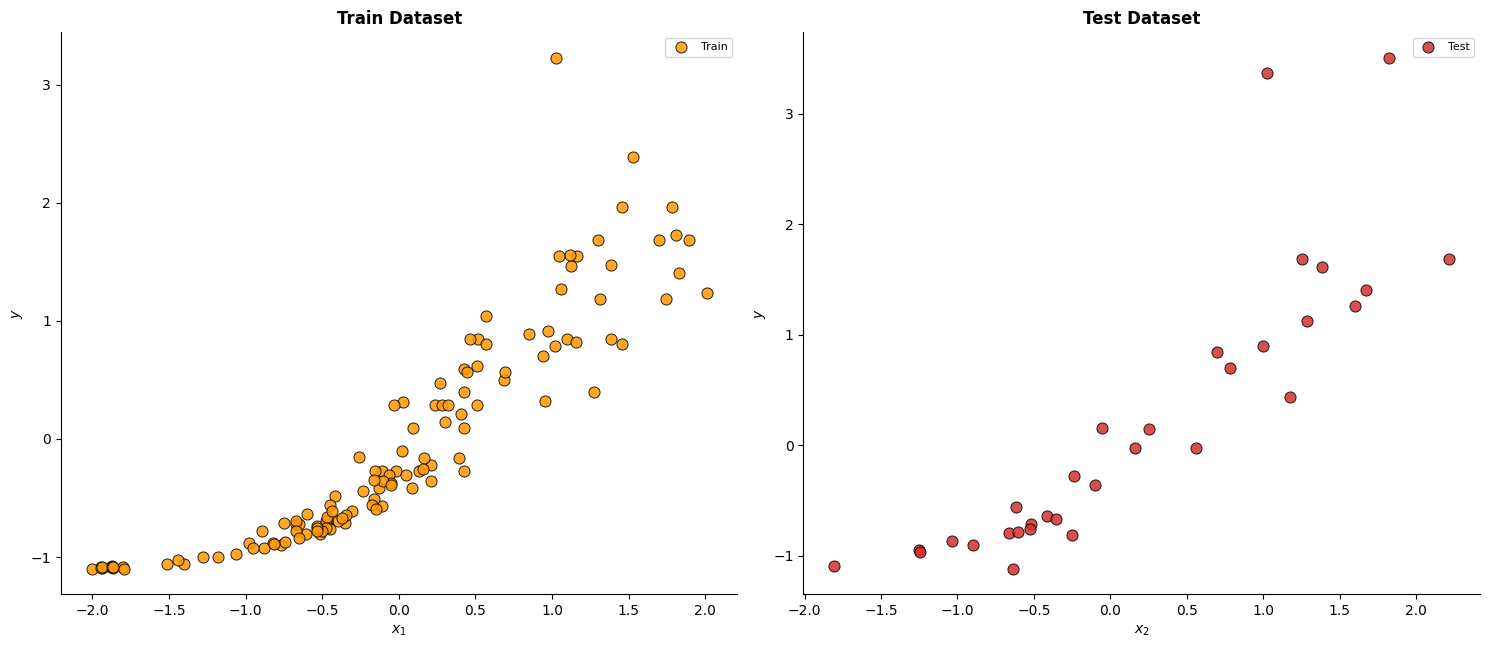

In [11]:
data = pd.read_csv('dataset.csv')

X = data[['x1']].values
y = data[['y']].values

# TODO: Split the data into training and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)

plot_train_test_scatter(X_train, y_train, X_test, y_test)

### Task 2: Train the model

In [13]:
print(y.shape)
print(y_train.shape)

(159, 1)
(127, 1)


In [14]:
# TODO: create instanse of model and train it.
model = LinearRegression(learning_rate=0.01, max_iterations=100)
model.fit(X_train, y_train)

Iteration 100/100, Cost: 1.375050


### Task 3: Experiments with Different Learning Rates

**Your Task**: Train models with different learning rates and compare their performance.


In [16]:
# TODO: Define different learning rates to experiment with
learning_rates = [0.0001,0.001,0.01,0.1]

# Dictionary to store trained models
lr_models = {}

# TODO: Train a model for each learning rate
for lr in learning_rates:
    print(f"\n--- Training with Learning Rate: {lr} ---")
    
    # TODO: Create and train model
    model = LinearRegression(learning_rate=lr, max_iterations=1000)
    model.fit(X_train, y_train)
    
    # Store model with descriptive name
    lr_models[f'LR={lr}'] = model
    
    # Print final cost and learned weights
    print(f"Final cost: {model.cost_history[-1]:.6f}")
    print(f"Learned weights: {model.get_weights()}")



--- Training with Learning Rate: 0.0001 ---
Iteration 100/1000, Cost: 0.866819
Iteration 200/1000, Cost: 0.868012
Iteration 300/1000, Cost: 0.869654
Iteration 400/1000, Cost: 0.871719
Iteration 500/1000, Cost: 0.874181
Iteration 600/1000, Cost: 0.877014
Iteration 700/1000, Cost: 0.880195
Iteration 800/1000, Cost: 0.883703
Iteration 900/1000, Cost: 0.887514
Iteration 1000/1000, Cost: 0.891610
Final cost: 0.891610
Learned weights: [-0.0005897   0.16855313]

--- Training with Learning Rate: 0.001 ---
Iteration 100/1000, Cost: 0.884084
Iteration 200/1000, Cost: 0.932606
Iteration 300/1000, Cost: 0.995734
Iteration 400/1000, Cost: 1.063249
Iteration 500/1000, Cost: 1.129251
Iteration 600/1000, Cost: 1.190571
Iteration 700/1000, Cost: 1.245732
Iteration 800/1000, Cost: 1.294275
Iteration 900/1000, Cost: 1.336335
Iteration 1000/1000, Cost: 1.372362
Final cost: 1.372362
Learned weights: [-0.02038261  0.72245762]

--- Training with Learning Rate: 0.01 ---
Iteration 100/1000, Cost: 1.373805
Ite

### Task 4: Visualize experiments using 'compare_predictions'

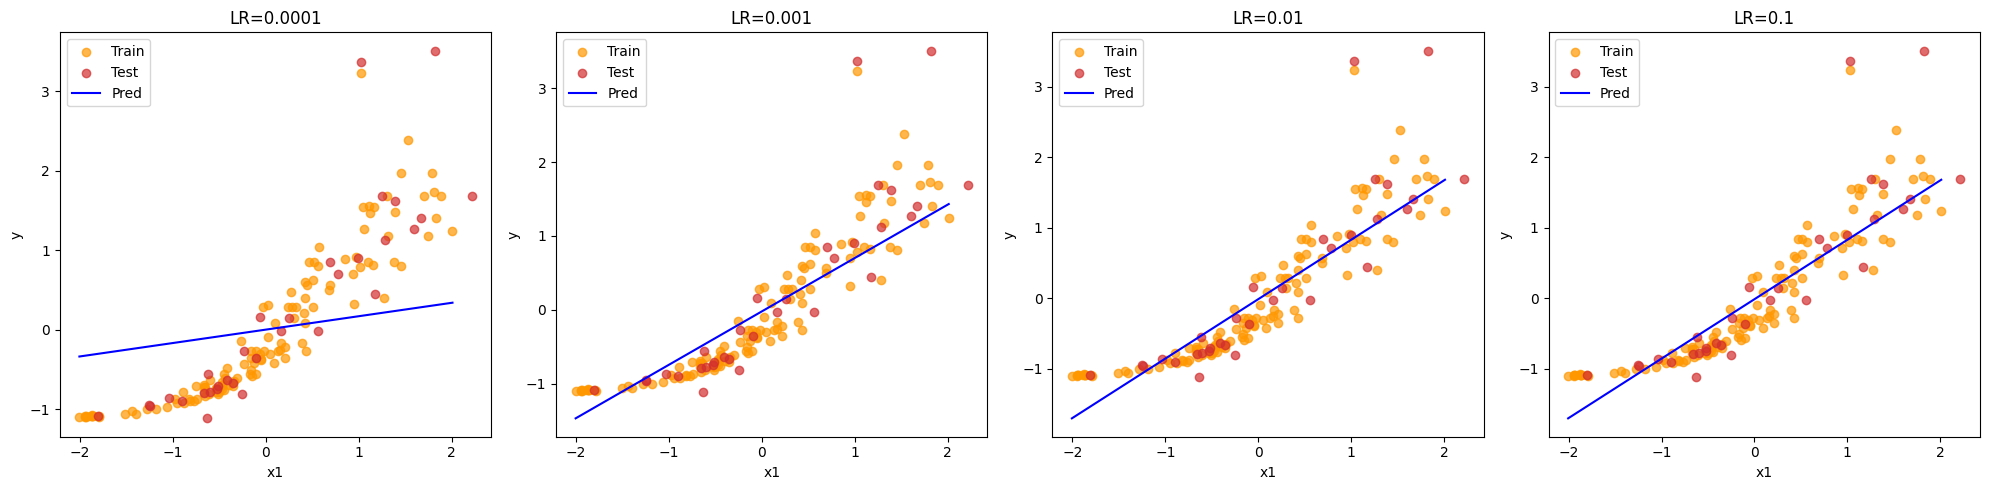

In [18]:
compare_predictions(X_train, X_test, y_train, y_test, lr_models)

In [19]:
from sklearn.metrics import  r2_score
r2_sc = r2_score(y_test, model.predict(X_test))
print(r2_sc)


0.7268549828814566


## Part 5: Train Multivariate Regrossion Model

### Task 1: Specify Input & Target (Multivariate Regression)

**Your Task**: Load and prepare the dataset for linear regression.

For the multivariate model, load the feature x_1 and feature x_1, then split the data into training and test sets with an 80/20 ratio.

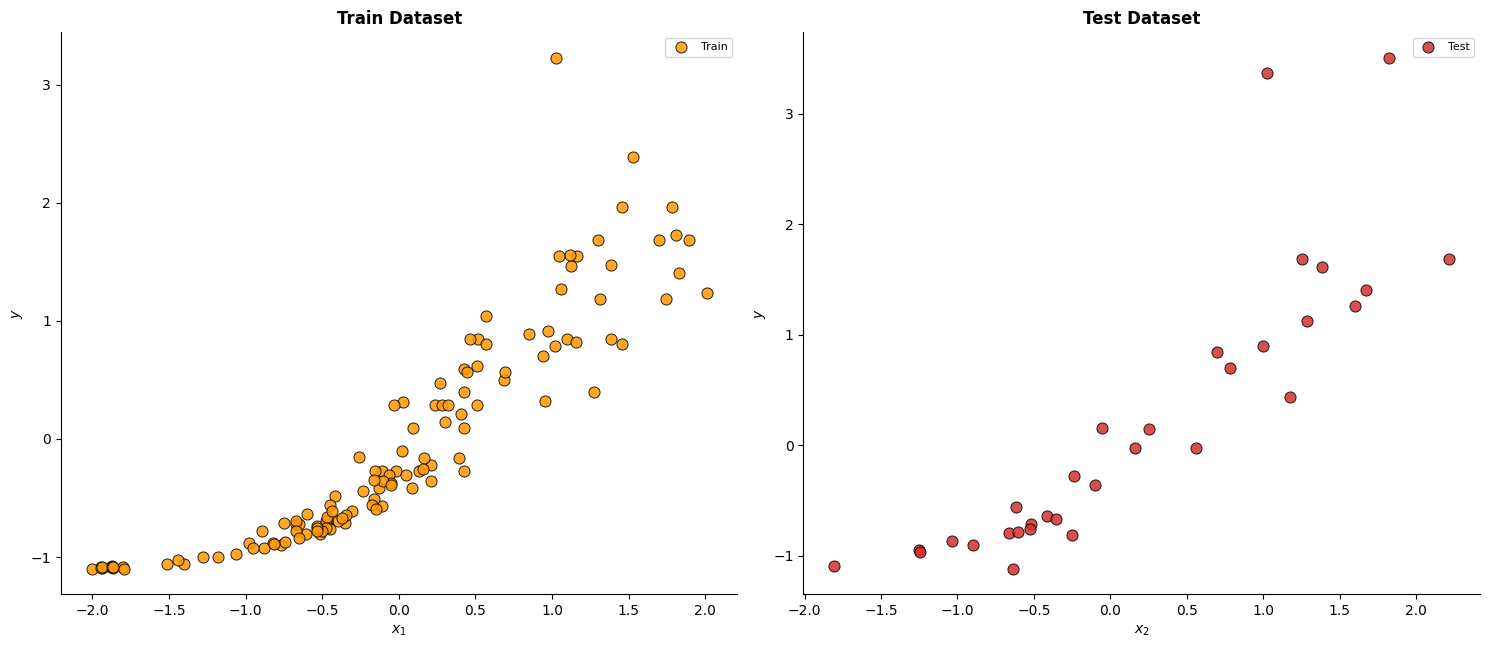

In [21]:
data = pd.read_csv('dataset.csv')

X =  data[['x1', 'x2']].values
y =  data['y'].values.ravel()

# TODO: Split the data into training and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)
plot_train_test_scatter(X_train[:, 0].reshape(-1, 1), y_train, X_test[:, 0].reshape(-1, 1), y_test)
X_train_multivariate, X_test_multivariate, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)

### Task 2: Train the model

In [23]:
# TODO: create instanse of model and train it.
model1 = LinearRegression(learning_rate=0.01, max_iterations=1000, regularization=None, lambda_reg=0.01)
model1.fit(X_train_multivariate, y_train)

Iteration 100/1000, Cost: 0.183945
Iteration 200/1000, Cost: 0.172553
Iteration 300/1000, Cost: 0.167667
Iteration 400/1000, Cost: 0.165496
Iteration 500/1000, Cost: 0.164532
Iteration 600/1000, Cost: 0.164104
Iteration 700/1000, Cost: 0.163914
Iteration 800/1000, Cost: 0.163829
Iteration 900/1000, Cost: 0.163792
Iteration 1000/1000, Cost: 0.163775


### Task 3: Experiments with Different Learning Rates

**Your Task**: Train models with different learning rates and compare their performance.

In [25]:
# TODO: Define different learning rates to experiment with
learning_rates = [0.001, 0.01, 0.1]

# Dictionary to store trained models
lr_models = {}

# TODO: Train a model for each learning rate
for lr in learning_rates:
    print(f"\n--- Training with Learning Rate: {lr} ---")
    
    # Create and train model
    model = LinearRegression(learning_rate=lr, max_iterations=1000)
    model.fit(X_train_multivariate, y_train)
    
    # Store model with descriptive name
    lr_models[f'LR={lr}'] = model
    
    # Print final cost and learned weights
    print(f"Final cost: {model.cost_history[-1]:.6f}")
    print(f"Learned weights: {model.get_weights()}")




--- Training with Learning Rate: 0.001 ---
Iteration 100/1000, Cost: 0.517208
Iteration 200/1000, Cost: 0.352063
Iteration 300/1000, Cost: 0.271223
Iteration 400/1000, Cost: 0.231033
Iteration 500/1000, Cost: 0.210494
Iteration 600/1000, Cost: 0.199497
Iteration 700/1000, Cost: 0.193177
Iteration 800/1000, Cost: 0.189186
Iteration 900/1000, Cost: 0.186389
Iteration 1000/1000, Cost: 0.184235
Final cost: 0.184235
Learned weights: [-0.02254292  0.51803595  0.31129501]

--- Training with Learning Rate: 0.01 ---
Iteration 100/1000, Cost: 0.184701
Iteration 200/1000, Cost: 0.172879
Iteration 300/1000, Cost: 0.167811
Iteration 400/1000, Cost: 0.165561
Iteration 500/1000, Cost: 0.164561
Iteration 600/1000, Cost: 0.164117
Iteration 700/1000, Cost: 0.163919
Iteration 800/1000, Cost: 0.163832
Iteration 900/1000, Cost: 0.163793
Iteration 1000/1000, Cost: 0.163776
Final cost: 0.163776
Learned weights: [-0.01606417  0.74964108  0.11040199]

--- Training with Learning Rate: 0.1 ---
Iteration 100/100

### Task 4: Visualize experiments using 'plot_cost_history'

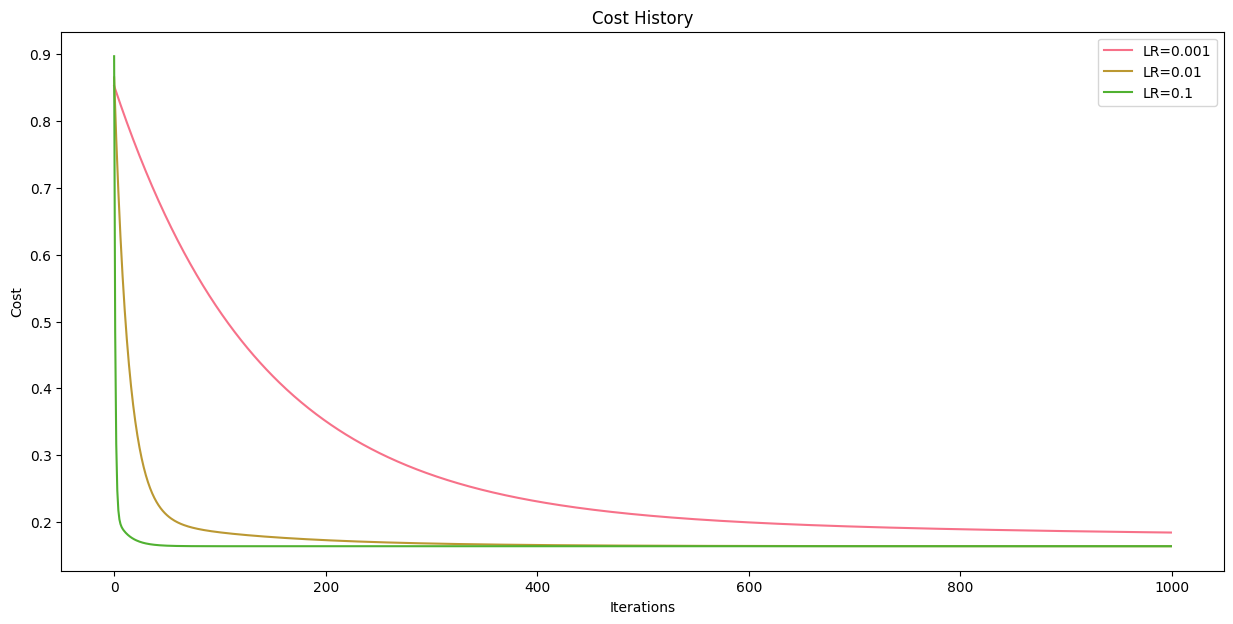

In [27]:
plot_cost_history(lr_models)

## Experiments with Different Learning Rates and Comparison of Learning Rates

In [29]:

learning_rates = [0.001, 0.01, 0.1]
results = {}
for lr in learning_rates:
    print(f"\n--- Training with Learning Rate: {lr} ---")
    model = LinearRegression(learning_rate=lr, max_iterations=1000, regularization=None, lambda_reg=0.01)
    model.fit(X_train_multivariate, y_train)
    mse, r2 = model.evaluate(X_test_multivariate, y_test)
    results[lr] = {'mse': mse, 'r2': r2, 'weights': model.get_weights()}
    print(f"MSE: {mse:.5f}, R-squared: {r2:.5f}")
    print(f"Learned Weights: {model.get_weights()}")

# Compare results
print("\nComparison of Learning Rates:")
for lr, metrics in results.items():
    print(f"Learning Rate {lr}: MSE = {metrics['mse']:.5f}, R-squared = {metrics['r2']:.5f}")


--- Training with Learning Rate: 0.001 ---
Iteration 100/1000, Cost: 0.515557
Iteration 200/1000, Cost: 0.352999
Iteration 300/1000, Cost: 0.273269
Iteration 400/1000, Cost: 0.233490
Iteration 500/1000, Cost: 0.213034
Iteration 600/1000, Cost: 0.201972
Iteration 700/1000, Cost: 0.195523
Iteration 800/1000, Cost: 0.191381
Iteration 900/1000, Cost: 0.188428
Iteration 1000/1000, Cost: 0.186122
MSE: 0.52609, R-squared: 0.64805
Learned Weights: [-0.02174569  0.50766506  0.32151531]

--- Training with Learning Rate: 0.01 ---
Iteration 100/1000, Cost: 0.184311
Iteration 200/1000, Cost: 0.172702
Iteration 300/1000, Cost: 0.167733
Iteration 400/1000, Cost: 0.165526
Iteration 500/1000, Cost: 0.164545
Iteration 600/1000, Cost: 0.164110
Iteration 700/1000, Cost: 0.163916
Iteration 800/1000, Cost: 0.163830
Iteration 900/1000, Cost: 0.163792
Iteration 1000/1000, Cost: 0.163775
MSE: 0.42617, R-squared: 0.71490
Learned Weights: [-0.01606248  0.74969912  0.11034634]

--- Training with Learning Rate: 0

## Part 6: Implement multivariative regression using sklearn

In [31]:
# TODO : use sklearn and implement multi-variative regression
from sklearn.linear_model import LinearRegression

import numpy as np
data = pd.read_csv('dataset.csv')
X = data[['x1', 'x2']].values  
y = data['y'].values.ravel()   
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)
sklearn_model = LinearRegression()
sklearn_model.fit(X_train, y_train)
y_pred = sklearn_model.predict(X_test)

## Calculate MSE and R-squared for both models

In [33]:
from sklearn.metrics import mean_squared_error, r2_score
mse_scratch = mean_squared_error(y_test, model1.predict(X_test_multivariate))
r2_scratch = r2_score(y_test, model1.predict(X_test_multivariate))
mse_sklearn = mean_squared_error(y_test, sklearn_model.predict(X_test_multivariate))
r2_sklearn = r2_score(y_test, sklearn_model.predict(X_test_multivariate))
print("Model Evaluation on Test Data:")
print(f"Scratch Model - MSE: {mse_scratch:.5f}, R-squared: {r2_scratch:.5f}")
print(f"Sklearn Model - MSE: {mse_sklearn:.5f}, R-squared: {r2_sklearn:.5f}")

Model Evaluation on Test Data:
Scratch Model - MSE: 0.42615, R-squared: 0.71491
Sklearn Model - MSE: 0.42448, R-squared: 0.71603


## visualization of results

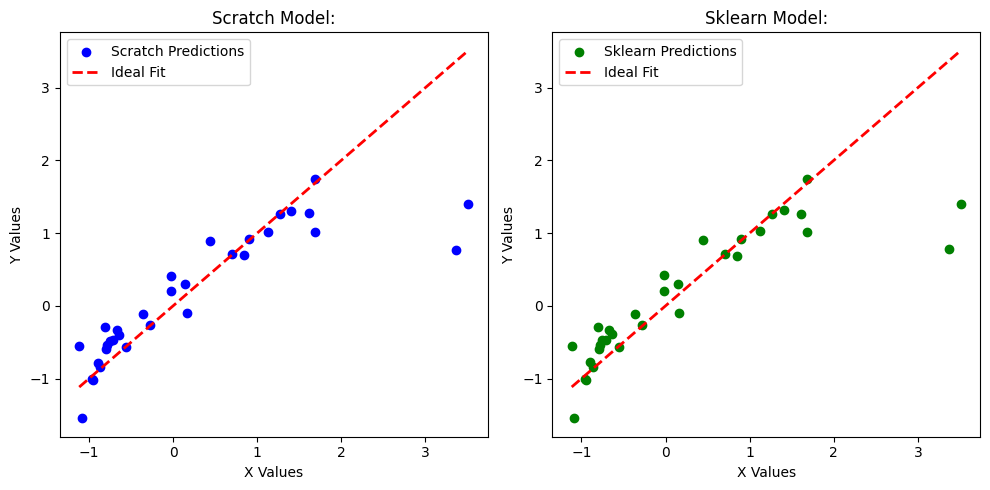


Error Analysis:
Scratch Model - Mean Error: 0.07967, Std Dev of Errors: 0.64792
Sklearn Model - Mean Error: 0.07896, Std Dev of Errors: 0.64672


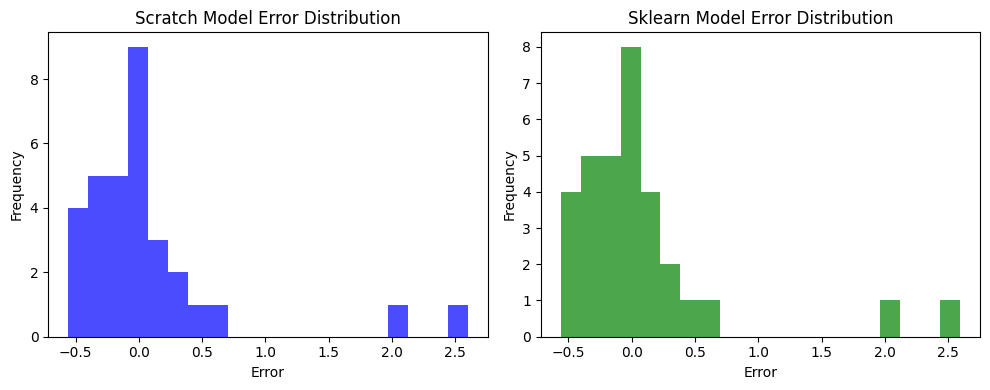

In [35]:
# Predict values for plotting
y_pred_scratch = model1.predict(X_test_multivariate)
y_pred_sklearn = sklearn_model.predict(X_test_multivariate)

# Plot actual vs. predicted points
plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.scatter(y_test, y_pred_scratch, color='blue', label='Scratch Predictions')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2, label='Ideal Fit')
plt.xlabel('X Values')
plt.ylabel('Y Values')
plt.title('Scratch Model:')
plt.legend()

plt.subplot(1, 2, 2)
plt.scatter(y_test, y_pred_sklearn, color='green', label='Sklearn Predictions')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2, label='Ideal Fit')
plt.xlabel('X Values')
plt.ylabel('Y Values')
plt.title('Sklearn Model:')
plt.legend()

plt.tight_layout()
plt.show()

# Error Analysis
errors_scratch = y_test - y_pred_scratch
errors_sklearn = y_test - y_pred_sklearn

print("\nError Analysis:")
print(f"Scratch Model - Mean Error: {np.mean(errors_scratch):.5f}, Std Dev of Errors: {np.std(errors_scratch):.5f}")
print(f"Sklearn Model - Mean Error: {np.mean(errors_sklearn):.5f}, Std Dev of Errors: {np.std(errors_sklearn):.5f}")

# Histogram of errors
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.hist(errors_scratch, bins=20, color='blue', alpha=0.7)
plt.title('Scratch Model Error Distribution')
plt.xlabel('Error')
plt.ylabel('Frequency')

plt.subplot(1, 2, 2)
plt.hist(errors_sklearn, bins=20, color='green', alpha=0.7)
plt.title('Sklearn Model Error Distribution')
plt.xlabel('Error')
plt.ylabel('Frequency')

plt.tight_layout()
plt.show()

## Part 7: Compare two models


In [37]:
# TODO: Calculate MSE loss for your models
scratch_predictions = model1.predict(X_test_multivariate)  # Fixed model1 to best_scratch_model
cost_skratch_multi = np.mean((scratch_predictions - y_test) ** 2)  # Correct MSE calculation
sklearn_predictions = sklearn_model.predict(X_test_multivariate)
cost_sklearn_multi = np.mean((sklearn_predictions - y_test) ** 2)  # Consistent MSE calculation
print('Final MSE of the scratch version on test dataset :', round(cost_skratch_multi, 5))
print('-------------------------------------------------------------------------------------------------')
print('Final MSE of the scikit-learn linear regression model on test dataset :', round(cost_sklearn_multi, 5))

Final MSE of the scratch version on test dataset : 0.42615
-------------------------------------------------------------------------------------------------
Final MSE of the scikit-learn linear regression model on test dataset : 0.42448
